In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn
print("Successfully installed the required libraries.")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: c:\Users\Norah Chisha\Desktop\CodeAlpha Virtual Internship\CodeAlpha_CreditScoringModel\.venv-1\Scripts\python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("All imports worked!")

pandas: 3.0.6
numpy: 2.5.4
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2
All imports worked!


In [5]:
df = pd.read_csv("data/cs-training.csv")
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [6]:
print("Shape:", df.shape)
print()
print(df.isnull().sum())
print()
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

Shape: (150000, 12)

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


In [7]:
df = df.drop(columns=["Unnamed: 0"])
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


In [8]:
print("Rows with age 0:", (df["age"] == 0).sum())
print()
print("Utilization above 1:", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print()
print(df["NumberOfTimes90DaysLate"].value_counts().sort_index().tail(6))

Rows with age 0: 1

Utilization above 1: 3321

NumberOfTimes90DaysLate
13      4
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64


In [9]:
df = df[df["age"] > 0]

late_codes = df["NumberOfTimes90DaysLate"] >= 96
print("Rows with code values:", late_codes.sum())
print("Default rate, code rows:", df.loc[late_codes, "SeriousDlqin2yrs"].mean())
print("Default rate, other rows:", df.loc[~late_codes, "SeriousDlqin2yrs"].mean())

Rows with code values: 269
Default rate, code rows: 0.5464684014869888
Default rate, other rows: 0.06597876177118814


In [10]:
late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]

# 1. Flag rows where any late column holds a code (96 or higher)
df["LateCodeFlag"] = (df[late_cols] >= 96).any(axis=1).astype(int)

# 2. Turn the code values into NaN
df[late_cols] = df[late_cols].where(df[late_cols] < 96)

print("Flagged rows:", df["LateCodeFlag"].sum())
print(df.groupby("LateCodeFlag")["SeriousDlqin2yrs"].mean())
print(df[late_cols].max())

Flagged rows: 269
LateCodeFlag
0    0.065979
1    0.546468
Name: SeriousDlqin2yrs, dtype: float64
NumberOfTime30-59DaysPastDueNotWorse    13.0
NumberOfTime60-89DaysPastDueNotWorse    11.0
NumberOfTimes90DaysLate                 17.0
dtype: float64


In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Default rate, train:", y_train.mean())
print("Default rate, test: ", y_test.mean())

Train: (119999, 11)  Test: (30000, 11)
Default rate, train: 0.06684222368519738
Default rate, test:  0.06683333333333333


In [12]:
# 1. Flag rows where income was missing (do this BEFORE filling)
X_train["IncomeMissing"] = X_train["MonthlyIncome"].isnull().astype(int)
X_test["IncomeMissing"] = X_test["MonthlyIncome"].isnull().astype(int)

# 2. Work out medians from the TRAINING set only
medians = X_train.median()

# 3. Fill gaps in both sets using those training medians
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Missing left (train, test):", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print()
print(medians[["MonthlyIncome", "NumberOfDependents"]])

Missing left (train, test): 0 0

MonthlyIncome         5400.0
NumberOfDependents       0.0
dtype: float64


In [13]:
cap_cols = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]

# 1. Work out the 99th percentile from the TRAINING set only
caps = X_train[cap_cols].quantile(0.99)

# 2. Cut anything above the cap, in both sets
X_train[cap_cols] = X_train[cap_cols].clip(upper=caps, axis=1)
X_test[cap_cols] = X_test[cap_cols].clip(upper=caps, axis=1)

print("Caps used:")
print(caps)
print()
print("New maximums (train):")
print(X_train[cap_cols].max())

Caps used:
RevolvingUtilizationOfUnsecuredLines        1.095907
DebtRatio                                4983.040000
MonthlyIncome                           23018.300000
Name: 0.99, dtype: float64

New maximums (train):
RevolvingUtilizationOfUnsecuredLines        1.095907
DebtRatio                                4983.040000
MonthlyIncome                           23018.300000
dtype: float64


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# 1. Scale: learn from train, apply to both
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 2. Train the model
model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)

# 3. Predict on the test set
pred = model.predict(X_test_s)
proba = model.predict_proba(X_test_s)[:, 1]

print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

           0       0.98      0.81      0.89     27995
           1       0.22      0.75      0.34      2005

    accuracy                           0.81     30000
   macro avg       0.60      0.78      0.61     30000
weighted avg       0.93      0.81      0.85     30000

ROC-AUC: 0.8616145116758024


In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200, max_depth=10, min_samples_leaf=50,
    class_weight="balanced", n_jobs=-1, random_state=42
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_proba))

              precision    recall  f1-score   support

           0       0.98      0.79      0.88     27995
           1       0.21      0.79      0.34      2005

    accuracy                           0.79     30000
   macro avg       0.60      0.79      0.61     30000
weighted avg       0.93      0.79      0.84     30000

ROC-AUC: 0.8670689591434879


RevolvingUtilizationOfUnsecuredLines    0.368
NumberOfTimes90DaysLate                 0.192
NumberOfTime30-59DaysPastDueNotWorse    0.187
NumberOfTime60-89DaysPastDueNotWorse    0.104
age                                     0.048
NumberOfOpenCreditLinesAndLoans         0.028
DebtRatio                               0.026
NumberRealEstateLoansOrLines            0.018
MonthlyIncome                           0.017
LateCodeFlag                            0.005
NumberOfDependents                      0.004
IncomeMissing                           0.003
dtype: float64


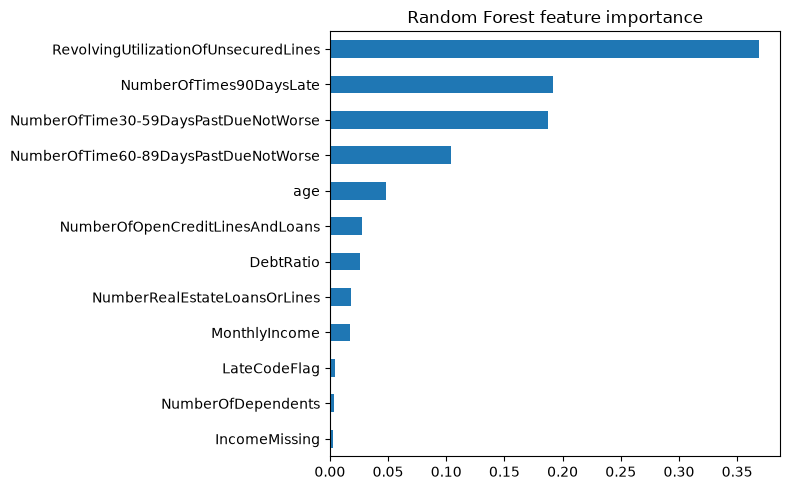

In [16]:
import matplotlib.pyplot as plt

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False).round(3))

importances.sort_values().plot(kind="barh", figsize=(8, 5),
                               title="Random Forest feature importance")
plt.tight_layout()
plt.show()

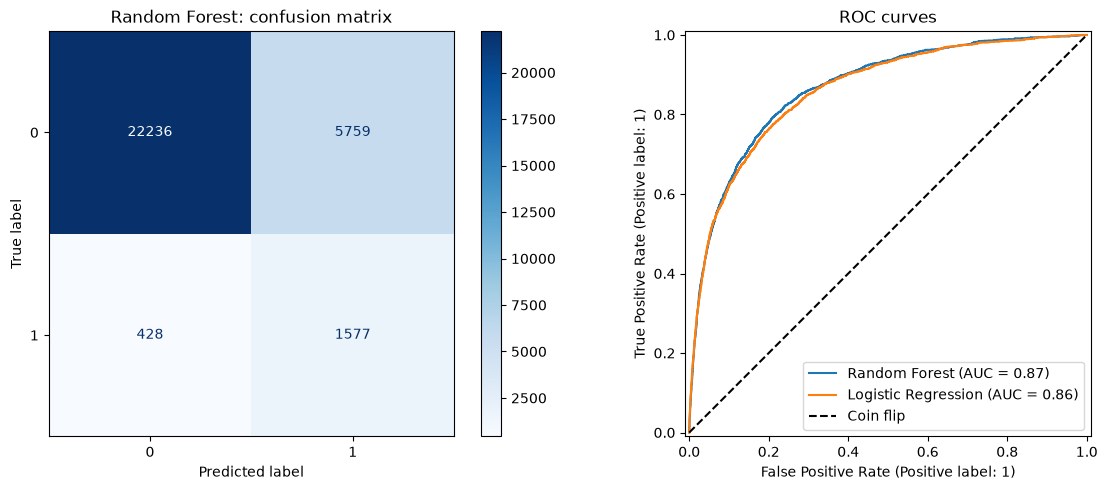

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, ax=ax[0], cmap="Blues")
ax[0].set_title("Random Forest: confusion matrix")

RocCurveDisplay.from_predictions(y_test, rf_proba, ax=ax[1], name="Random Forest")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1], name="Logistic Regression")
ax[1].plot([0, 1], [0, 1], "k--", label="Coin flip")
ax[1].set_title("ROC curves")
ax[1].legend()

plt.tight_layout()
plt.show()

In [26]:
def score(applicant):
    row = pd.DataFrame([applicant])
    row["IncomeMissing"] = 0
    row["LateCodeFlag"] = 0
    row = row[X_train.columns]  # same column order as training
    return rf.predict_proba(row)[0, 1]

safe = {
    "RevolvingUtilizationOfUnsecuredLines": 1.0, "age": 45,
    "NumberOfTime30-59DaysPastDueNotWorse": 0, "DebtRatio": 0.2,
    "MonthlyIncome": 9000, "NumberOfOpenCreditLinesAndLoans": 8,
    "NumberOfTimes90DaysLate": 0, "NumberRealEstateLoansOrLines": 1,
    "NumberOfTime60-89DaysPastDueNotWorse": 0, "NumberOfDependents": 1,
}

risky = {
    "RevolvingUtilizationOfUnsecuredLines":  1.0, "age": 26,
    "NumberOfTime30-59DaysPastDueNotWorse": 3, "DebtRatio": 0.9,
    "MonthlyIncome": 2500, "NumberOfOpenCreditLinesAndLoans": 12,
    "NumberOfTimes90DaysLate": 2, "NumberRealEstateLoansOrLines": 0,
    "NumberOfTime60-89DaysPastDueNotWorse": 1, "NumberOfDependents": 3,
}

print("Safe applicant risk score: ", round(score(safe), 3))
print("Risky applicant risk score:", round(score(risky), 3))

Safe applicant risk score:  0.445
Risky applicant risk score: 0.957


In [27]:
%pip freeze > requirements.txt

with open(".gitignore", "w") as f:
    f.write(".venv/\n.venv-1/\ndata/\n__pycache__/\n.ipynb_checkpoints/\n")

print(open("requirements.txt").read()[:300])

Note: you may need to restart the kernel to use updated packages.
asttokens==3.0.2
cloudpickle==3.1.2
colorama==0.4.6
comm==0.2.3
contourpy==1.4.0
cycler==0.12.1
debugpy==1.8.22
executing==2.3.0
fonttools==4.66.1
ipykernel==7.4.0
ipython==9.17.1
ipython_pygments_lexers==1.1.1
jedi==0.20.1
joblib==1.6.0
jupyter_client==8.10.0
jupyter_core==5.9.1
kiwisolver==1.5.1
m
